# Moving interference

This independent notebook compares beamformers when the interference
direction changes smoothly or abruptly. It reuses the existing 256
Monte Carlo simulations and their settings selected using 64 separate
validation simulations. It does not generate data or change a tracker.

The individual and combined exports are optional figures for the main paper. Their names
are separate from the existing beamforming figures; the earlier abrupt
export remains available as `abrupt_previous_main.pdf`.

In [1]:
from pathlib import Path
import sys
import os

# Use the session's existing TeX tools only when they are available.
LOCAL_TEX = Path('/workspace/.local/tex')
if (LOCAL_TEX / 'usr/bin/dvipng').exists():
    os.environ['PATH'] = str(LOCAL_TEX / 'usr/bin') + os.pathsep + os.environ['PATH']
    os.environ.setdefault('TEXMFHOME', str(LOCAL_TEX / 'usr/share/texmf'))
import numpy as np
import pandas as pd
from IPython.display import display

candidates = [Path.cwd(), *Path.cwd().parents]
ROOT = next(path for path in candidates if (path / "lib" / "beamforming_moving_evidence.py").is_file())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from lib.beamforming_moving_evidence import load_moving_evidence
EDITABLE_OUTPUT = ROOT / "results" / "beamforming_moving" / "figures"

## Measurements and estimates

For a half-wavelength uniform linear array, let
$b(\varphi)=n^{-1/2}[1,e^{\mathrm i\pi\sin\varphi},\ldots,
e^{\mathrm i\pi(n-1)\sin\varphi}]^\top$ and $a=b(0)$. The measurements are
$u_t=h_tc_t+e_t$, with $h_t=b(\varphi_t)$,
$c_t\sim\mathcal{CN}(0,\tau^2)$ and
$e_t\sim\mathcal{CN}(0,\sigma^2 I_n)$.
The initial angle $\varphi_0$ satisfies $|a^{\mathrm H}b(\varphi_0)|^2=1/2$.

The tracker starts from $A_0=0$ and uses $G_t=I_n$ and
$A_t^+=\beta A_{t-1}^++\tau^2u_tu_t^{\mathrm H}/[\sigma^2(\sigma^2+\tau^2)]$
up to an irrelevant identity term. The mean, mode and isotropic mean
use this same corrected parameter and $\beta=0.97$.
The isotropic mean preserves the mode and expected squared chordal
distance: with $\zeta_t=1-\operatorname{tr}(\overline P_t^+P_{\widehat{\mathcal X}_t})$,
$\overline P_t^{\mathrm{iso}}=(1-\zeta_t)P_{\widehat{\mathcal X}_t}
+\zeta_t(I_n-P_{\widehat{\mathcal X}_t})/(n-1)$.
GREAT uses the same snapshots with its independently selected sliding
window and finite number of Grassmann updates.

In [2]:
# Numerical configuration of the verified saved experiment.
# Plotting controls are independent and appear in each figure cell.
CONFIG = dict(n=32, T=256, beta=0.97, sigma2=0.2, tau2=1.0,
              conditions=["smooth", "abrupt"],
              methods=["mean", "mode", "iso", "great_window"])
G_t = np.eye(CONFIG["n"])
A_0 = np.zeros((CONFIG["n"], CONFIG["n"]), dtype=complex)
display(pd.DataFrame([{
    "n": CONFIG["n"], "T": CONFIG["T"], "beta": CONFIG["beta"],
    "sigma2": CONFIG["sigma2"], "tau2": CONFIG["tau2"],
    "G_t": "I_n", "A_0": "0",
}]))

,n,T,beta,sigma2,tau2,G_t,A_0
0,32,256,0.97,0.2,1.0,I_n,0


## Output power

For each matrix $D_t$, the beamformer is
$w_t=(\sigma^2 I_n+\tau^2D_t)^{-1}a/
[a^{\mathrm H}(\sigma^2 I_n+\tau^2D_t)^{-1}a]$.
We evaluate
$\ell_t=10\log_{10}[w_t^{\mathrm H}R_tw_t/p_t^\star]$,
where $R_t=\sigma^2 I_n+\tau^2h_th_t^{\mathrm H}$ and
$p_t^\star=(a^{\mathrm H}R_t^{-1}a)^{-1}$.
The generating covariance is used for evaluation only. A smaller value
means lower output power under the common unit-gain constraint.

The loader verifies the saved source hashes, settings and simulation
identifiers. Curves show means across 256 Monte Carlo simulations.
Shaded regions show the pointwise 25th–75th percentiles across simulations.
These are empirical spreads of the simulated output powers, not posterior
credible regions. The tables retain their original Student 95% confidence
intervals for the means at the recorded indices $t=8,16,\ldots,256$.

In [3]:
data = load_moving_evidence(ROOT, CONFIG)
assert list(data["conditions"]) == CONFIG["conditions"]
assert all(len(curve["points"]) == 32
           for condition in CONFIG["conditions"]
           for curve in data["conditions"][condition]["curves"])
print("Verified saved experiments:", ", ".join(CONFIG["conditions"]))
print("Reporting indices:", data["conditions"]["smooth"]["time"].tolist())
print("Initial angle (degrees):", np.rad2deg(data["config"]["phi0_rad"]))

Verified saved experiments: smooth, abrupt
Reporting indices: [8, 16, 24, 32, 40, 48, 56, 64, 72, 80, 88, 96, 104, 112, 120, 128, 136, 144, 152, 160, 168, 176, 184, 192, 200, 208, 216, 224, 232, 240, 248, 256]
Initial angle (degrees): 1.5870570261349242


## Numerical comparison

Define $\overline\ell=\frac1{32}\sum_{j=1}^{32}\ell_{8j}$ within each
simulation, then average these 256 values. This is an arithmetic
average of the exact per-measurement dB values, including the initial
measurements. It differs from the older moving-study summary that
takes the logarithm after averaging power ratios and omits an initial
interval.

The paired table uses the same simulation identifiers for every method.
Its difference is $\overline\ell_{\mathrm{reference}}-
\overline\ell_{\mathrm{posterior\ mean}}$; positive values favor the
posterior mean and negative values favor the reference.

In [4]:
METHOD_LABELS = {
    "mean": "Posterior mean", "mode": "Mode",
    "iso": "Isotropic mean", "great_window": "GREAT (sliding window)",
}
summary = data["time_average_summary"].copy()
summary["method"] = summary["method"].map(METHOD_LABELS)
display(summary.rename(columns={"condition": "Condition", "method": "Method",
    "simulations": "Simulations", "mean": "Mean (dB)",
    "lower": "Lower 95%", "upper": "Upper 95%"}).round(4))

paired = data["paired_time_average_summary"].copy()
paired["reference"] = paired["reference"].map(METHOD_LABELS)
display(paired.rename(columns={"condition": "Condition", "reference": "Reference",
    "simulations": "Pairs", "mean": "Difference (dB)",
    "lower": "Lower 95%", "upper": "Upper 95%"}).round(4))

# Optional checkpoint detail; the complete arrays remain local in data.
SHOW_CHECKPOINT_TABLE = False
CHECKPOINT_T = 256
if SHOW_CHECKPOINT_TABLE:
    display(data["checkpoint_summary"].query("t == @CHECKPOINT_T").round(4))
    display(data["paired_checkpoint_summary"].query("t == @CHECKPOINT_T").round(4))

,Condition,Method,Simulations,Mean (dB),Lower 95%,Upper 95%
0,smooth,Posterior mean,256,0.3298,0.3227,0.3368
1,smooth,Mode,256,0.3307,0.3233,0.3381
2,smooth,Isotropic mean,256,0.3318,0.3247,0.3390
3,smooth,GREAT (sliding window),256,0.2962,0.2900,0.3025
4,abrupt,Posterior mean,256,0.6802,0.6686,0.6918
5,abrupt,Mode,256,0.6646,0.6525,0.6768
6,abrupt,Isotropic mean,256,0.6948,0.6829,0.7066
7,abrupt,GREAT (sliding window),256,0.6936,0.6840,0.7033


,Condition,Reference,Pairs,Difference (dB),Lower 95%,Upper 95%
0,smooth,Mode,256,0.0009,-0.0008,0.0025
1,smooth,Isotropic mean,256,0.0020,0.0018,0.0023
2,smooth,GREAT (sliding window),256,-0.0335,-0.0375,-0.0296
3,abrupt,Mode,256,-0.0156,-0.0177,-0.0134
4,abrupt,Isotropic mean,256,0.0146,0.0138,0.0154
5,abrupt,GREAT (sliding window),256,0.0135,0.0062,0.0207


## Smooth motion

Here $\varphi_t=\varphi_0+
2\varphi_0(t-1)/(T-1)$. The direction moves continuously from
$\varphi_0$ to $3\varphi_0$ over all 256 measurements.
This comparison shows the interaction between accumulated information
and tracking a changing interference direction.

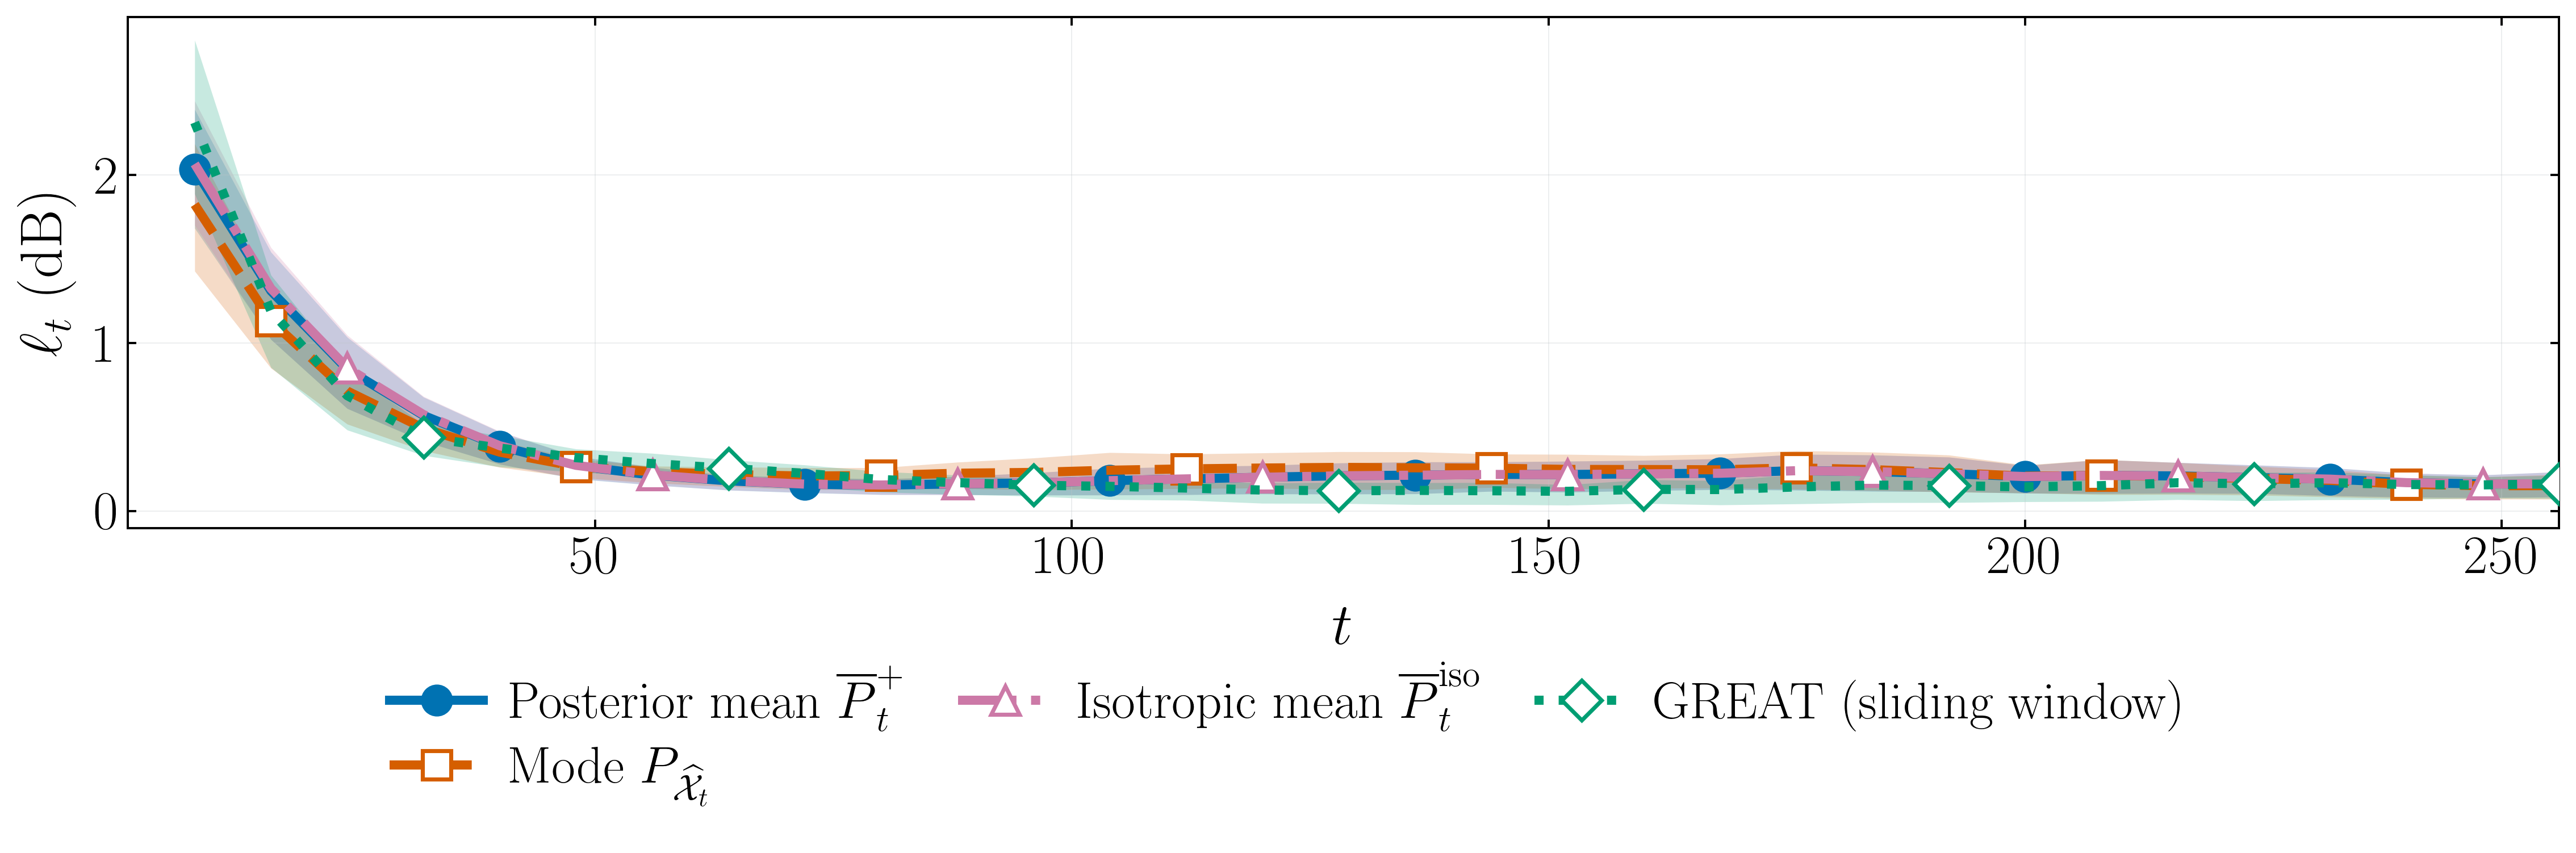

In [5]:
# Edit these plotting controls independently for this figure.
import matplotlib.pyplot as plt

DPI = 300
FIGSIZE = (15, 5)
LABEL_FONT_SIZE = 25.0
TICK_FONT_SIZE = 23.0
LEGEND_FONT_SIZE = 22.0
PRINT_WIDTH_IN = 7.
PRINT_SCALE = FIGSIZE[0] / PRINT_WIDTH_IN
LINE_WIDTH = 1.8 * PRINT_SCALE
MARKER_SIZE = 5.5 * PRINT_SCALE
SPINE_WIDTH = 0.95
IQR_ALPHA = 0.22
SHOW_IQR = {"mean": True, "mode": True, "iso": True, "great_window": True}
SAVE_PDF = True
SAVE_PNG = True
COPY_MAIN_CANDIDATE = True
PDF_PATH = EDITABLE_OUTPUT / 'moving_interference_smooth_output_power.pdf'
PNG_PATH = PDF_PATH.with_suffix('.png')
DRAFT_SECTION = 'main'
DRAFT_PATH = ROOT / 'results' / DRAFT_SECTION / 'beamforming' / PDF_PATH.name
DRAFT_PNG_PATH = DRAFT_PATH.with_suffix('.png')

plt.rcParams.update({
    "text.usetex": True,
    "text.latex.preamble": r"\usepackage{amsmath}\usepackage{amssymb}",
    "font.family": "serif", "font.size": LABEL_FONT_SIZE,
    "axes.labelsize": LABEL_FONT_SIZE,
    "xtick.labelsize": TICK_FONT_SIZE, "ytick.labelsize": TICK_FONT_SIZE,
    "legend.fontsize": LEGEND_FONT_SIZE, "axes.labelpad": 8.0,
    "figure.dpi": DPI, "savefig.dpi": DPI, "savefig.bbox": None,
    "lines.linewidth": LINE_WIDTH, "lines.markersize": MARKER_SIZE,
    "axes.spines.top": True, "axes.spines.right": True,
    "axes.spines.bottom": True, "axes.spines.left": True,
})

STYLE = {
    "mean": (r"Posterior mean $\overline P_t^+$", "#0072B2", "o", "-"),
    "mode": (r"Mode $P_{\widehat{\mathcal X}_t}$", "#D55E00", "s", "--"),
    "iso": (r"Isotropic mean $\overline P_t^{\mathrm{iso}}$", "#CC79A7", "^", "-."),
    "great_window": ("GREAT (sliding window)", "#009E73", "D", ":"),
}
MARKER_OFFSETS = {"mean": 0, "mode": 1, "iso": 2, "great_window": 3}

fig, ax = plt.subplots(figsize=FIGSIZE, dpi=DPI, layout="constrained")
panels = [(ax, 'smooth')]

for ax, condition in panels:
    plot_data = data["conditions"][condition]
    samples = data["checkpoint_losses"]
    samples = samples[samples["condition"].eq(condition)]
    # Empirical quartiles across the actual 256 simulations, not CI endpoints.
    quantiles = samples.groupby(["method", "t"])["true_ratio_db"].quantile([0.25, 0.75]).unstack()

    # All empirical bands are behind every mean curve.
    for curve in plot_data["curves"]:
        method = curve["method"]
        label, color_, marker_, linestyle_ = STYLE[method]
        points = curve["points"]  # columns t, mean, lower95, upper95; mean is unchanged
        quartiles = quantiles.loc[method].reindex(points[:, 0])
        if SHOW_IQR[method]:
            ax.fill_between(points[:, 0], quartiles[0.25].to_numpy(), quartiles[0.75].to_numpy(),
                            color=color_, alpha=IQR_ALPHA, linewidth=0., zorder=1)
    for curve in plot_data["curves"]:
        method = curve["method"]
        label, color_, marker_, linestyle_ = STYLE[method]
        points = curve["points"]
        ax.plot(points[:, 0], points[:, 1], color=color_, marker=marker_,
                linestyle=linestyle_, label=label, linewidth=LINE_WIDTH,
                markersize=MARKER_SIZE, markevery=(MARKER_OFFSETS[method], 4),
                markerfacecolor=color_ if method == "mean" else "white",
                markeredgecolor=color_, markeredgewidth=.8 * PRINT_SCALE, zorder=10)
    if condition == "abrupt":
        ax.axvline(129, color="#7B3294", linewidth=1.3, linestyle="--", zorder=20,
                   label="Direction change")
    ax.set(xlabel=r"$t$", ylabel=r"$\ell_t$ (dB)", xlim=(1, 256))
    for spine in ax.spines.values():
        spine.set_linewidth(SPINE_WIDTH)
    ax.tick_params(axis="both", which="both", direction="in", top=True, right=True,
                   bottom=True, left=True, labelbottom=True, labelleft=True,
                   labeltop=False, labelright=False, width=SPINE_WIDTH)
    ax.grid(color="#BFC4C8", alpha=.30, linewidth=.45)

handles, labels = [], []
for ax, condition in panels:
    for handle, label in zip(*ax.get_legend_handles_labels()):
        if label not in labels:
            handles.append(handle)
            labels.append(label)
fig.legend(handles, labels, loc="outside lower center", ncol=3,
           frameon=False, fontsize=LEGEND_FONT_SIZE, columnspacing=1.,
           handlelength=1.8, handletextpad=.5, labelspacing=.3)
layout = fig.get_layout_engine()
if layout is not None and hasattr(layout, "set"):
    layout.set(h_pad=.04, w_pad=.04)

if SAVE_PDF:
    PDF_PATH.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(PDF_PATH, dpi=DPI, bbox_inches=None, metadata={"Title": ""})
    if SAVE_PNG:
        fig.savefig(PNG_PATH, dpi=DPI, bbox_inches=None)
    if COPY_MAIN_CANDIDATE:
        DRAFT_PATH.parent.mkdir(parents=True, exist_ok=True)
        DRAFT_PATH.write_bytes(PDF_PATH.read_bytes())
        if SAVE_PNG:
            DRAFT_PNG_PATH.write_bytes(PNG_PATH.read_bytes())
plt.show()

## Abrupt motion

Here $\varphi_t=\varphi_0$ through $t=128$ and
$\varphi_t=3\varphi_0$ from $t=129$. The dashed line marks that change.
The transient increase in output power and subsequent decrease show
the response to a newly changed interference direction.

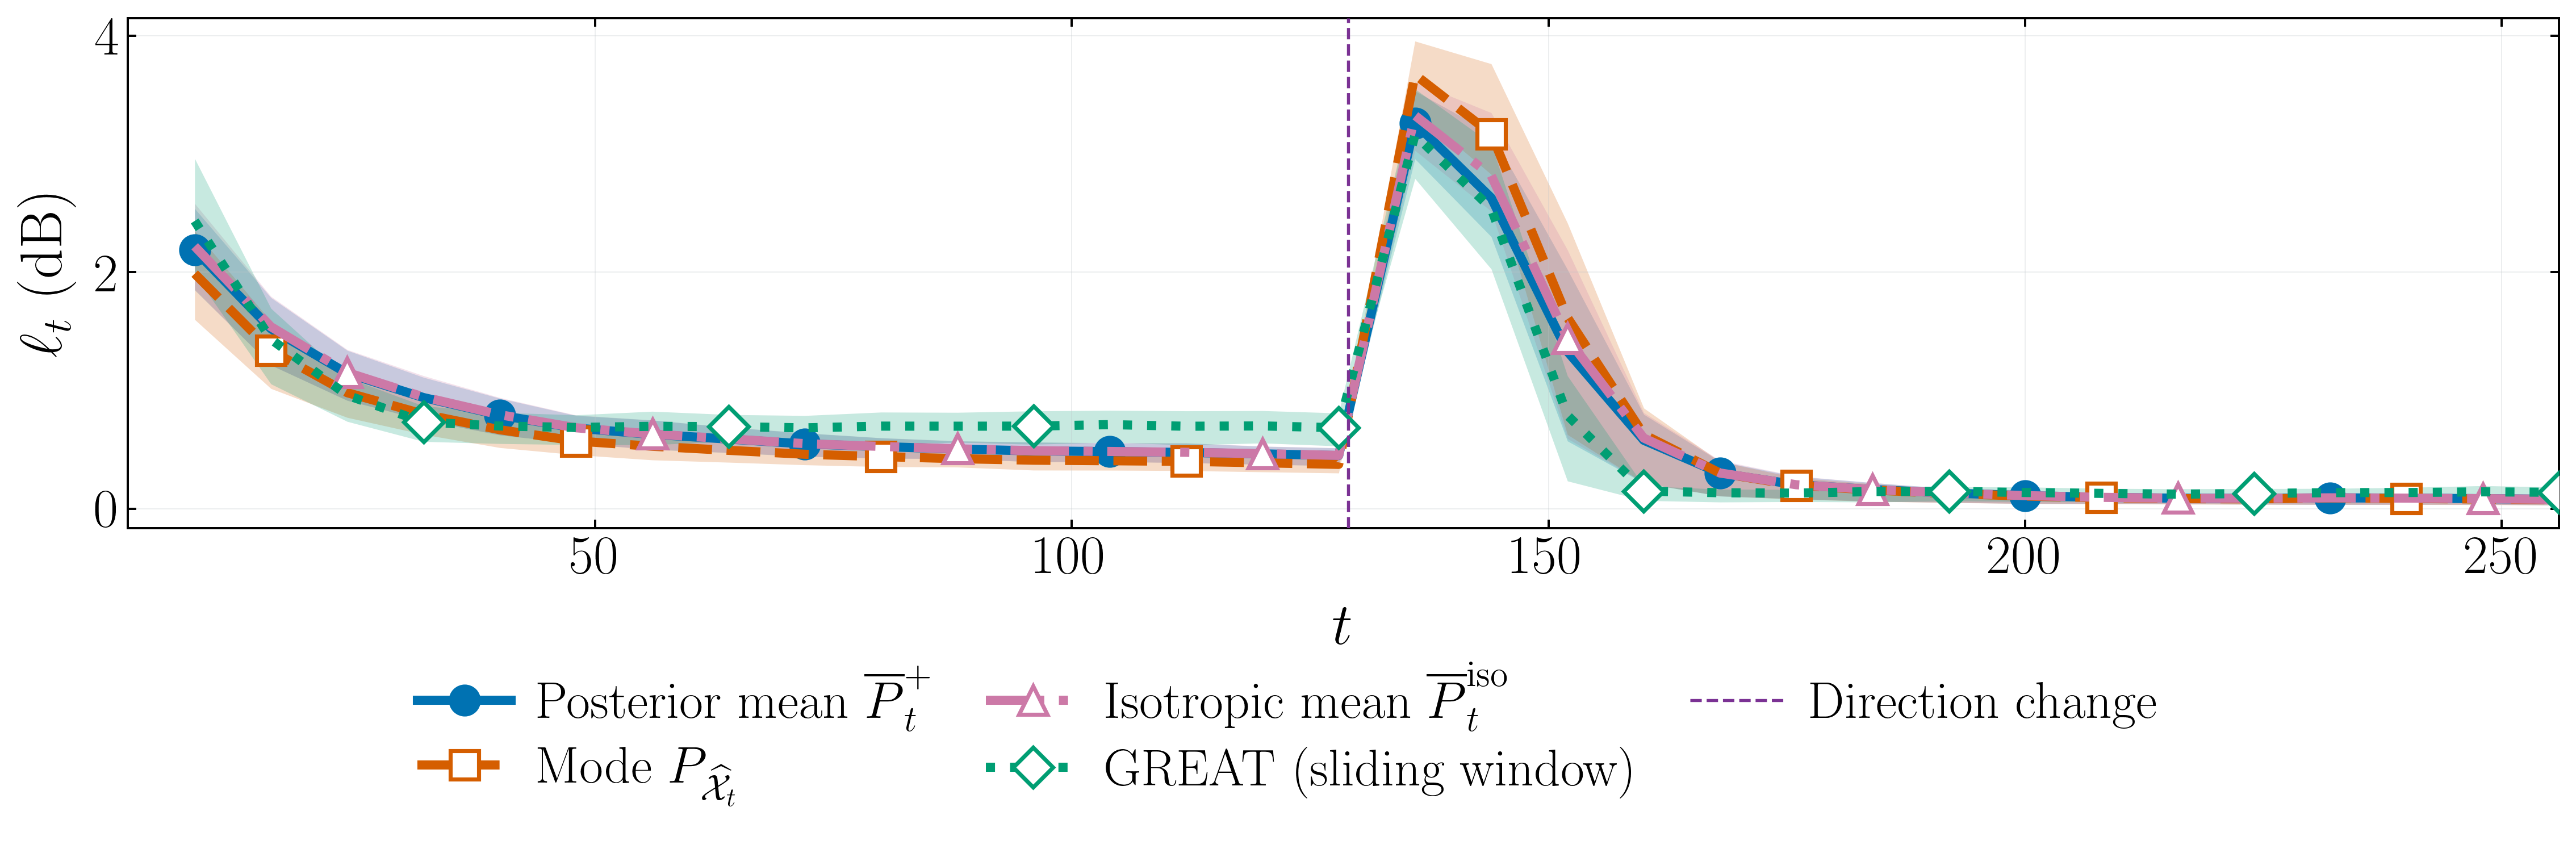

In [6]:
# Edit these plotting controls independently for this figure.
import matplotlib.pyplot as plt

DPI = 300
FIGSIZE = (15, 5)
LABEL_FONT_SIZE = 25.0
TICK_FONT_SIZE = 23.0
LEGEND_FONT_SIZE = 22.0
PRINT_WIDTH_IN = 7.
PRINT_SCALE = FIGSIZE[0] / PRINT_WIDTH_IN
LINE_WIDTH = 1.8 * PRINT_SCALE
MARKER_SIZE = 5.5 * PRINT_SCALE
SPINE_WIDTH = 0.95
IQR_ALPHA = 0.22
SHOW_IQR = {"mean": True, "mode": True, "iso": True, "great_window": True}
SAVE_PDF = True
SAVE_PNG = True
COPY_MAIN_CANDIDATE = True
PDF_PATH = EDITABLE_OUTPUT / 'moving_interference_abrupt_output_power.pdf'
PNG_PATH = PDF_PATH.with_suffix('.png')
DRAFT_SECTION = 'main'
DRAFT_PATH = ROOT / 'results' / DRAFT_SECTION / 'beamforming' / PDF_PATH.name
DRAFT_PNG_PATH = DRAFT_PATH.with_suffix('.png')

plt.rcParams.update({
    "text.usetex": True,
    "text.latex.preamble": r"\usepackage{amsmath}\usepackage{amssymb}",
    "font.family": "serif", "font.size": LABEL_FONT_SIZE,
    "axes.labelsize": LABEL_FONT_SIZE,
    "xtick.labelsize": TICK_FONT_SIZE, "ytick.labelsize": TICK_FONT_SIZE,
    "legend.fontsize": LEGEND_FONT_SIZE, "axes.labelpad": 8.0,
    "figure.dpi": DPI, "savefig.dpi": DPI, "savefig.bbox": None,
    "lines.linewidth": LINE_WIDTH, "lines.markersize": MARKER_SIZE,
    "axes.spines.top": True, "axes.spines.right": True,
    "axes.spines.bottom": True, "axes.spines.left": True,
})

STYLE = {
    "mean": (r"Posterior mean $\overline P_t^+$", "#0072B2", "o", "-"),
    "mode": (r"Mode $P_{\widehat{\mathcal X}_t}$", "#D55E00", "s", "--"),
    "iso": (r"Isotropic mean $\overline P_t^{\mathrm{iso}}$", "#CC79A7", "^", "-."),
    "great_window": ("GREAT (sliding window)", "#009E73", "D", ":"),
}
MARKER_OFFSETS = {"mean": 0, "mode": 1, "iso": 2, "great_window": 3}

fig, ax = plt.subplots(figsize=FIGSIZE, dpi=DPI, layout="constrained")
panels = [(ax, 'abrupt')]

for ax, condition in panels:
    plot_data = data["conditions"][condition]
    samples = data["checkpoint_losses"]
    samples = samples[samples["condition"].eq(condition)]
    # Empirical quartiles across the actual 256 simulations, not CI endpoints.
    quantiles = samples.groupby(["method", "t"])["true_ratio_db"].quantile([0.25, 0.75]).unstack()

    # All empirical bands are behind every mean curve.
    for curve in plot_data["curves"]:
        method = curve["method"]
        label, color_, marker_, linestyle_ = STYLE[method]
        points = curve["points"]  # columns t, mean, lower95, upper95; mean is unchanged
        quartiles = quantiles.loc[method].reindex(points[:, 0])
        if SHOW_IQR[method]:
            ax.fill_between(points[:, 0], quartiles[0.25].to_numpy(), quartiles[0.75].to_numpy(),
                            color=color_, alpha=IQR_ALPHA, linewidth=0., zorder=1)
    for curve in plot_data["curves"]:
        method = curve["method"]
        label, color_, marker_, linestyle_ = STYLE[method]
        points = curve["points"]
        ax.plot(points[:, 0], points[:, 1], color=color_, marker=marker_,
                linestyle=linestyle_, label=label, linewidth=LINE_WIDTH,
                markersize=MARKER_SIZE, markevery=(MARKER_OFFSETS[method], 4),
                markerfacecolor=color_ if method == "mean" else "white",
                markeredgecolor=color_, markeredgewidth=.8 * PRINT_SCALE, zorder=10)
    if condition == "abrupt":
        ax.axvline(129, color="#7B3294", linewidth=1.3, linestyle="--", zorder=20,
                   label="Direction change")
    ax.set(xlabel=r"$t$", ylabel=r"$\ell_t$ (dB)", xlim=(1, 256))
    for spine in ax.spines.values():
        spine.set_linewidth(SPINE_WIDTH)
    ax.tick_params(axis="both", which="both", direction="in", top=True, right=True,
                   bottom=True, left=True, labelbottom=True, labelleft=True,
                   labeltop=False, labelright=False, width=SPINE_WIDTH)
    ax.grid(color="#BFC4C8", alpha=.30, linewidth=.45)

handles, labels = [], []
for ax, condition in panels:
    for handle, label in zip(*ax.get_legend_handles_labels()):
        if label not in labels:
            handles.append(handle)
            labels.append(label)
fig.legend(handles, labels, loc="outside lower center", ncol=3,
           frameon=False, fontsize=LEGEND_FONT_SIZE, columnspacing=1.,
           handlelength=1.8, handletextpad=.5, labelspacing=.3)
layout = fig.get_layout_engine()
if layout is not None and hasattr(layout, "set"):
    layout.set(h_pad=.04, w_pad=.04)

if SAVE_PDF:
    PDF_PATH.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(PDF_PATH, dpi=DPI, bbox_inches=None, metadata={"Title": ""})
    if SAVE_PNG:
        fig.savefig(PNG_PATH, dpi=DPI, bbox_inches=None)
    if COPY_MAIN_CANDIDATE:
        DRAFT_PATH.parent.mkdir(parents=True, exist_ok=True)
        DRAFT_PATH.write_bytes(PDF_PATH.read_bytes())
        if SAVE_PNG:
            DRAFT_PNG_PATH.write_bytes(PNG_PATH.read_bytes())
plt.show()

## Combined comparison

Curves show means across 256 Monte Carlo simulations. Shaded regions show the pointwise 25th–75th percentiles across simulations.

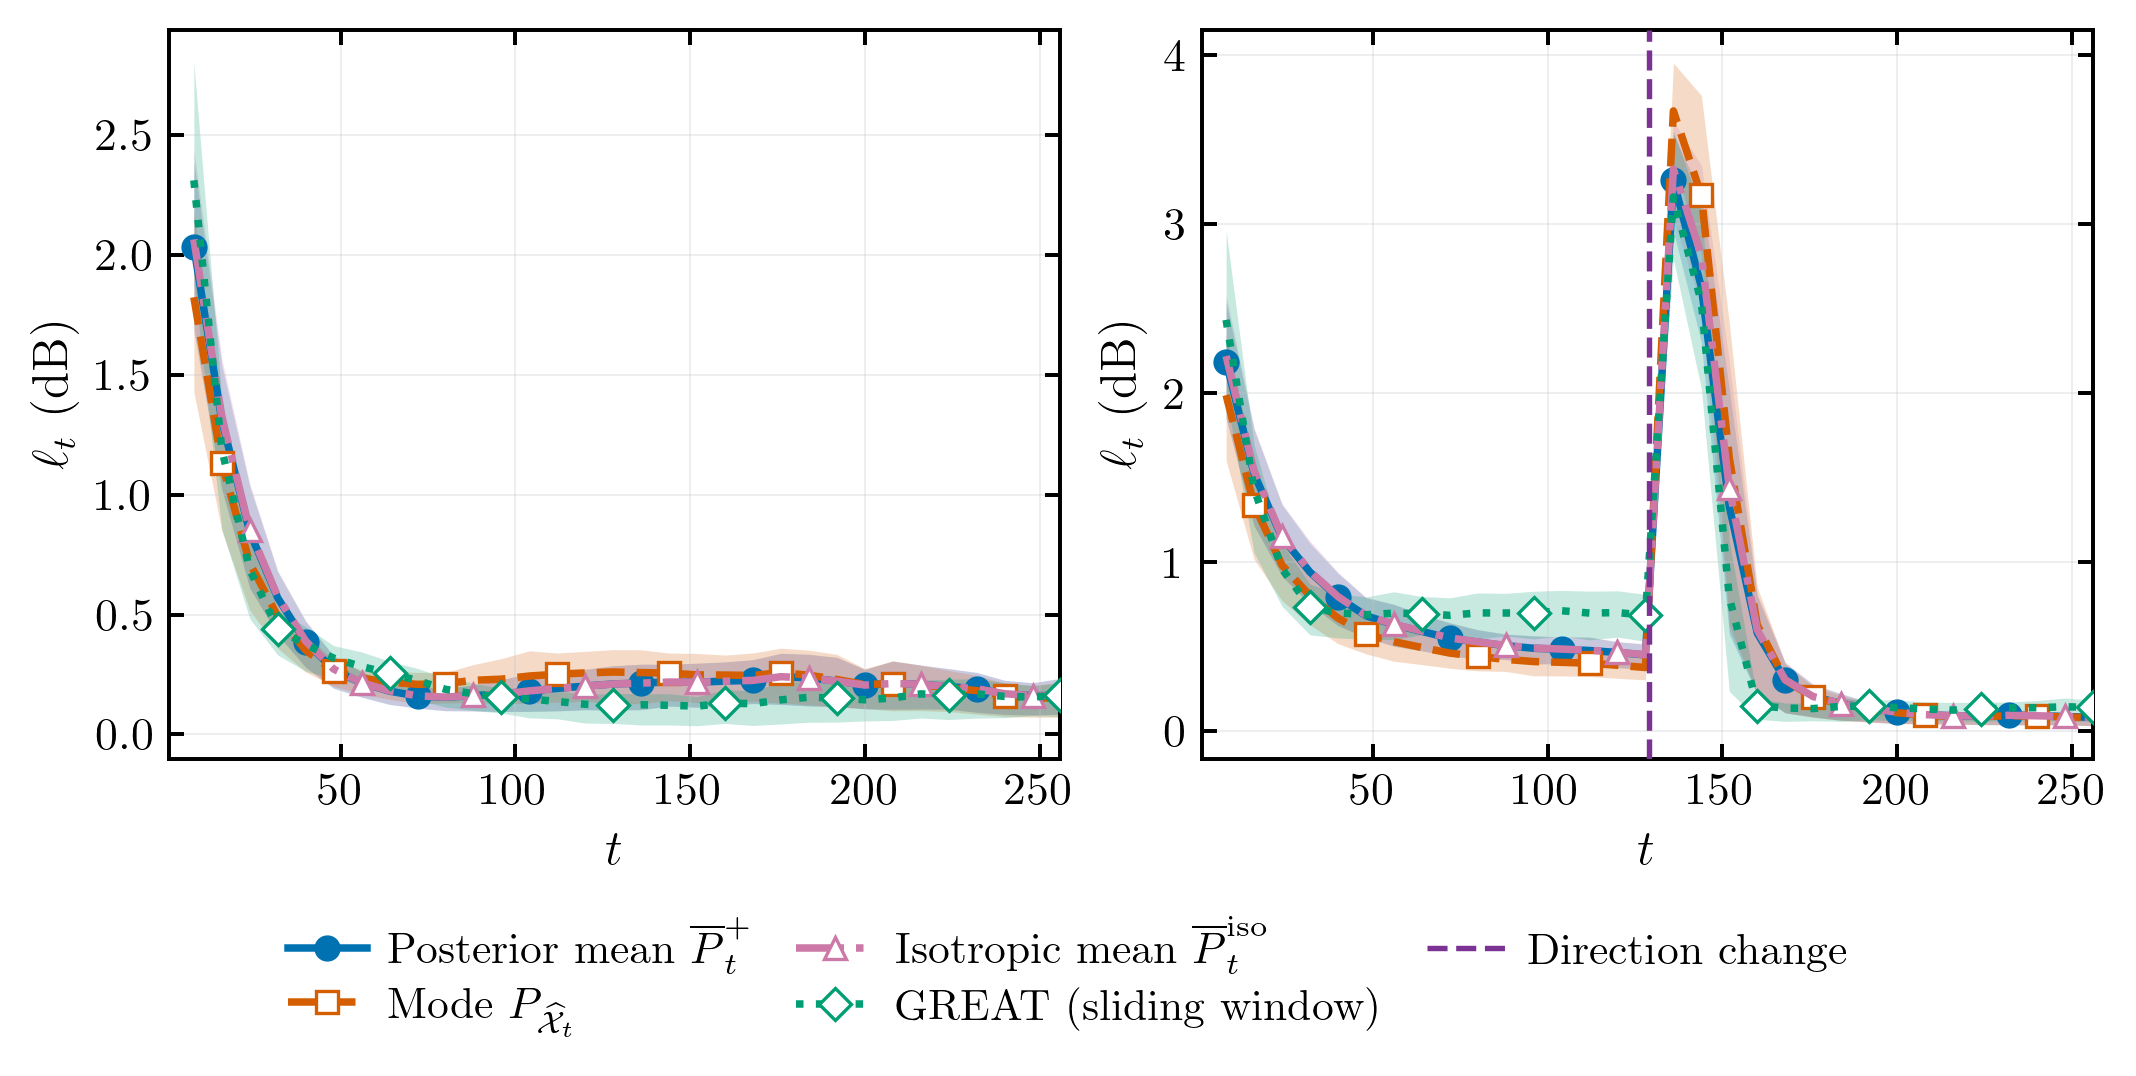

In [7]:
# Edit these plotting controls independently for this figure.
import matplotlib.pyplot as plt

DPI = 300
FIGSIZE = (7, 3.5)
LABEL_FONT_SIZE = 12.0
TICK_FONT_SIZE = 11.0
LEGEND_FONT_SIZE = 10.5
PRINT_WIDTH_IN = 7.
PRINT_SCALE = FIGSIZE[0] / PRINT_WIDTH_IN
LINE_WIDTH = 1.8 * PRINT_SCALE
MARKER_SIZE = 5.5 * PRINT_SCALE
SPINE_WIDTH = 0.95
IQR_ALPHA = 0.22
SHOW_IQR = {"mean": True, "mode": True, "iso": True, "great_window": True}
SAVE_PDF = True
SAVE_PNG = True
COPY_MAIN_CANDIDATE = True
PDF_PATH = EDITABLE_OUTPUT / 'moving_interference_comparison.pdf'
PNG_PATH = PDF_PATH.with_suffix('.png')
DRAFT_SECTION = 'main'
DRAFT_PATH = ROOT / 'results' / DRAFT_SECTION / 'beamforming' / PDF_PATH.name
DRAFT_PNG_PATH = DRAFT_PATH.with_suffix('.png')

plt.rcParams.update({
    "text.usetex": True,
    "text.latex.preamble": r"\usepackage{amsmath}\usepackage{amssymb}",
    "font.family": "serif", "font.size": LABEL_FONT_SIZE,
    "axes.labelsize": LABEL_FONT_SIZE,
    "xtick.labelsize": TICK_FONT_SIZE, "ytick.labelsize": TICK_FONT_SIZE,
    "legend.fontsize": LEGEND_FONT_SIZE, "axes.labelpad": 4.0,
    "figure.dpi": DPI, "savefig.dpi": DPI, "savefig.bbox": None,
    "lines.linewidth": LINE_WIDTH, "lines.markersize": MARKER_SIZE,
    "axes.spines.top": True, "axes.spines.right": True,
    "axes.spines.bottom": True, "axes.spines.left": True,
})

STYLE = {
    "mean": (r"Posterior mean $\overline P_t^+$", "#0072B2", "o", "-"),
    "mode": (r"Mode $P_{\widehat{\mathcal X}_t}$", "#D55E00", "s", "--"),
    "iso": (r"Isotropic mean $\overline P_t^{\mathrm{iso}}$", "#CC79A7", "^", "-."),
    "great_window": ("GREAT (sliding window)", "#009E73", "D", ":"),
}
MARKER_OFFSETS = {"mean": 0, "mode": 1, "iso": 2, "great_window": 3}

fig, axes = plt.subplots(1, 2, figsize=FIGSIZE, dpi=DPI, layout="constrained")
panels = list(zip(axes, ("smooth", "abrupt")))

for ax, condition in panels:
    plot_data = data["conditions"][condition]
    samples = data["checkpoint_losses"]
    samples = samples[samples["condition"].eq(condition)]
    # Empirical quartiles across the actual 256 simulations, not CI endpoints.
    quantiles = samples.groupby(["method", "t"])["true_ratio_db"].quantile([0.25, 0.75]).unstack()

    # All empirical bands are behind every mean curve.
    for curve in plot_data["curves"]:
        method = curve["method"]
        label, color_, marker_, linestyle_ = STYLE[method]
        points = curve["points"]  # columns t, mean, lower95, upper95; mean is unchanged
        quartiles = quantiles.loc[method].reindex(points[:, 0])
        if SHOW_IQR[method]:
            ax.fill_between(points[:, 0], quartiles[0.25].to_numpy(), quartiles[0.75].to_numpy(),
                            color=color_, alpha=IQR_ALPHA, linewidth=0., zorder=1)
    for curve in plot_data["curves"]:
        method = curve["method"]
        label, color_, marker_, linestyle_ = STYLE[method]
        points = curve["points"]
        ax.plot(points[:, 0], points[:, 1], color=color_, marker=marker_,
                linestyle=linestyle_, label=label, linewidth=LINE_WIDTH,
                markersize=MARKER_SIZE, markevery=(MARKER_OFFSETS[method], 4),
                markerfacecolor=color_ if method == "mean" else "white",
                markeredgecolor=color_, markeredgewidth=.8 * PRINT_SCALE, zorder=10)
    if condition == "abrupt":
        ax.axvline(129, color="#7B3294", linewidth=1.3, linestyle="--", zorder=20,
                   label="Direction change")
    ax.set(xlabel=r"$t$", ylabel=r"$\ell_t$ (dB)", xlim=(1, 256))
    for spine in ax.spines.values():
        spine.set_linewidth(SPINE_WIDTH)
    ax.tick_params(axis="both", which="both", direction="in", top=True, right=True,
                   bottom=True, left=True, labelbottom=True, labelleft=True,
                   labeltop=False, labelright=False, width=SPINE_WIDTH)
    ax.grid(color="#BFC4C8", alpha=.30, linewidth=.45)

handles, labels = [], []
for ax, condition in panels:
    for handle, label in zip(*ax.get_legend_handles_labels()):
        if label not in labels:
            handles.append(handle)
            labels.append(label)
fig.legend(handles, labels, loc="outside lower center", ncol=3,
           frameon=False, fontsize=LEGEND_FONT_SIZE, columnspacing=1.,
           handlelength=1.8, handletextpad=.5, labelspacing=.3)
layout = fig.get_layout_engine()
if layout is not None and hasattr(layout, "set"):
    layout.set(h_pad=.04, w_pad=.04)

if SAVE_PDF:
    PDF_PATH.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(PDF_PATH, dpi=DPI, bbox_inches=None, metadata={"Title": ""})
    if SAVE_PNG:
        fig.savefig(PNG_PATH, dpi=DPI, bbox_inches=None)
    if COPY_MAIN_CANDIDATE:
        DRAFT_PATH.parent.mkdir(parents=True, exist_ok=True)
        DRAFT_PATH.write_bytes(PDF_PATH.read_bytes())
        if SAVE_PNG:
            DRAFT_PNG_PATH.write_bytes(PNG_PATH.read_bytes())
plt.show()

## Interpretation

Comparing the posterior mean with the mode tests the effect of
averaging subspace uncertainty. Comparing it with the isotropic mean
tests the effect of retaining uncertainty differences between
directions. The GREAT comparison uses its selected window and update
settings; the tables retain both favorable and unfavorable differences.
Sliding-window GREAT has lower time-averaged output power than the
posterior mean during smooth motion. The ordering reverses in the
abrupt experiment. The mode has lower time-averaged power than the
posterior mean in the abrupt case; the smooth comparison with the mode
has a paired interval containing zero. The isotropic comparisons show
a modest benefit from retaining directional uncertainty. These are
comparisons for the declared motion and signal-to-noise settings.

$G_t=I_n$ specifies the coordinate transport. It does not predict the
physical direction changes: forgetting handles them here. These plots
evaluate output power and do not establish calibrated posterior
coverage during unmodeled motion. The optional main-paper copies use
new filenames and do not replace an existing figure.